# Instagram Likes Review · Derek Galperin · September 21, 2026

#### Data about the "Galperin Photo" Instagram account, data is provided by Meta.

#### This data was created as a full breakdown of user data that Meta collects. It can be used to see interests and what companies target advertisements to the user. 

#### This data is reliable in reporting facts such as what posts the user liked, who they follow, who follows them and who the user has blocked.

#### This data might be unreliable when looking at advertisers to find interests, or when infering interests based on liked posts. It is more likely to be unreliable when analyzing and infering. 

In [1]:
import json
import pandas as pd

with open('liked_posts.json', 'r') as f:
    data = json.load(f)

data[0]

{'timestamp': 1788207380,
 'media': [],
 'label_values': [{'label': 'URL',
   'value': 'https://www.instagram.com/reel/Dct2cflRGGx/',
   'href': 'https://www.instagram.com/reel/Dct2cflRGGx/'},
  {'label': 'Caption',
   'value': 'You donâ\x80\x99t know it yet, but some of your favorite memories are about to happen.\nThe people youâ\x80\x99ll meet. The laughs youâ\x80\x99ll share. The little moments that somehow become the ones you remember most.\nWelcome to the beginning of it all, Flashes. #KentState'},
  {'label': 'Title', 'value': ''},
  {'label': 'Caption',
   'value': 'You donâ\x80\x99t know it yet, but some of your favorite memories are about to happen.\nThe people youâ\x80\x99ll meet. The laughs youâ\x80\x99ll share. The little moments that somehow become the ones you remember most.\nWelcome to the beginning of it all, Flashes. #KentState'},
  {'label': 'Title', 'value': ''},
  {'dict': [{'dict': [{'label': 'Name', 'value': 'kentstate'}], 'title': ''}],
   'title': 'Hashtags'},
 

In [3]:
row = {}
row['timestamp'] = data[0]['timestamp']

row

{'timestamp': 1788207380}

In [6]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']

row

{'URL': 'https://www.instagram.com/reel/Dct2cflRGGx/',
 'Caption': 'You donâ\x80\x99t know it yet, but some of your favorite memories are about to happen.\nThe people youâ\x80\x99ll meet. The laughs youâ\x80\x99ll share. The little moments that somehow become the ones you remember most.\nWelcome to the beginning of it all, Flashes. #KentState',
 'Title': ''}

In [12]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']
    elif item.get('title') == 'Owner':
        owner_fields = item['dict'][0]['dict']
        for owner_item in owner_fields:
            row['Owner ' + owner_item['label']] = owner_item['value']


row

{'URL': 'https://www.instagram.com/reel/Dct2cflRGGx/',
 'Caption': 'You donâ\x80\x99t know it yet, but some of your favorite memories are about to happen.\nThe people youâ\x80\x99ll meet. The laughs youâ\x80\x99ll share. The little moments that somehow become the ones you remember most.\nWelcome to the beginning of it all, Flashes. #KentState',
 'Title': '',
 'Owner URL': 'https://sprout.link/kentstate',
 'Owner Name': 'Kent State University',
 'Owner Username': 'kentstate'}

In [13]:
tidy_rows = []

for entry in data:
    row = {}
    row['timestamp'] = entry['timestamp']

    for item in entry['label_values']:
        if 'label' in item:
            row[item['label']] = item['value']
        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']
            for owner_item in owner_fields:
                row['Owner ' + owner_item['label']] = owner_item['value']
    tidy_rows.append(row)

tidy_rows[:2]

[{'timestamp': 1788207380,
  'URL': 'https://www.instagram.com/reel/Dct2cflRGGx/',
  'Caption': 'You donâ\x80\x99t know it yet, but some of your favorite memories are about to happen.\nThe people youâ\x80\x99ll meet. The laughs youâ\x80\x99ll share. The little moments that somehow become the ones you remember most.\nWelcome to the beginning of it all, Flashes. #KentState',
  'Title': '',
  'Owner URL': 'https://sprout.link/kentstate',
  'Owner Name': 'Kent State University',
  'Owner Username': 'kentstate'},
 {'timestamp': 1788186658,
  'URL': 'https://www.instagram.com/p/DctTgwzlvkkuIzL_eD6Vj-pESiSTWDBw92Ht7A0/',
  'Caption': 'Summer 2026 - From the UK, blimp rides to standing in a hot air balloon, this summer really had it all. I took so many photos @galperinphoto and made some great memories!',
  'Title': '',
  'Owner URL': 'http://www.derekgalperin.photography',
  'Owner Name': 'Derek',
  'Owner Username': 'derekgalp'}]

In [16]:
likes_df = pd.DataFrame(tidy_rows)
likes_df.head(10)

,timestamp,URL,Caption,Title,Owner URL,Owner Name,Owner Username
0,1788207380,https://www.instagram.com/reel/Dct2cflRGGx/,"You donât know it yet, but some of your favo...",,https://sprout.link/kentstate,Kent State University,kentstate
1,1788186658,https://www.instagram.com/p/DctTgwzlvkkuIzL_eD...,"Summer 2026 - From the UK, blimp rides to stan...",,http://www.derekgalperin.photography,Derek,derekgalp
2,1788028916,https://www.instagram.com/p/DceOsBboBB6/,The Iowa State Fair in Des Moines is the large...,,https://linkin.bio/gettyimages,Getty Images,gettyimages
3,1788028892,https://www.instagram.com/p/Dck3Zsxm8UE/,It was a bit too cloudy to get a good look at ...,,http://ferrero.photo,Dash Ferrero,dashferrero
4,1788028867,https://www.instagram.com/p/Dcogdb6lLcx/,first game w the ð¸ \n\n#YoungstownState #Co...,,,jackson shannon,sackjannon
5,1787864516,https://www.instagram.com/p/DchUGJ5IClbqXWOz3u...,Tame Impala ð\n\nTame Impala ð\n\nTame I...,,,Nolan Miller,nomill22
6,1787662647,https://www.instagram.com/p/DcUSRztndzu/,Kinda chic to be a Lions photographer #oneprid...,,https://www.detroitlions.com/purchasephotos,Lions Photography,lionsphotog
7,1787601383,https://www.instagram.com/p/DcbxNigH-Xj/,"And we're so back. Happy first day of classes,...",,https://sprout.link/kentstate,Kent State University,kentstate
8,1787574078,https://www.instagram.com/p/DcZyzYrDsGB/,The evening before the first day of classes wa...,,https://sprout.link/kentstate,Kent State University,kentstate
9,1787512429,https://www.instagram.com/p/Db0two1jlol/,"Another year, another unforgettable National B...",,https://www.grantwebsterphoto.com/,Grant Webster,grantwebsterphoto


In [20]:
likes_df['DateTime'] = pd.to_datetime(likes_df['timestamp'], unit='s')
likes_df[['timestamp', 'DateTime']].head()

,timestamp,DateTime
0,1788207380,2026-08-31 20:16:20
1,1788186658,2026-08-31 14:30:58
2,1788028916,2026-08-29 18:41:56
3,1788028892,2026-08-29 18:41:32
4,1788028867,2026-08-29 18:41:07


In [23]:
likes_df['Owner Username'].isna().sum()

np.int64(0)

In [24]:
likes_df.dtypes

timestamp                 int64
URL                         str
Caption                     str
Title                       str
Owner URL                   str
Owner Name                  str
Owner Username              str
DateTime          datetime64[s]
dtype: object

In [26]:
likes_by_account = (
    likes_df.groupby("Owner Username")["DateTime"]
        .count()
        .sort_values(ascending=False)
)
likes_by_account.head(10)

Owner Username
kentstate             59
gettymotorsport       11
f1                    11
getmediaprod          10
laryea_media          10
gettysport             9
lucascochranmedia      7
jakesmakesandtakes     7
bobchristy1            6
kentstfootball         5
Name: DateTime, dtype: int64

I believe that my targeted advertisements using the advertisers_using_your_activity_or_information.json file will  reflect the top liked posts on my account. 

I am going to test this by comparing the top groups within the advertisements and see how they compare to the top 10 accounts. In order to make this comparision, I believe that I would need 60% of the top liked posts to be in the advertisement data. I will categorize the top ten as such:

1. Universtiy/College
2. Racing/Motorsport
3. Racing/Motorsport
4. Media/Creative
5. Media/Creative
6. Media/Creative
7. Media/Creative
8. Media/Creative
9. Media/Creative
10. Sports/Athletic

Therefore I would need my top ads to be media or creative based companies for my hypothesis to be true. 

I am going to use the advertisers_using_your_activity_or_information.json file to test my hypothesis because I believe it contains information regarding companies that have targeted me with advertisements. 

In [7]:
import json

with open('advertisers_using_your_activity_or_information.json', 'r') as g:
    advert = json.load(g)

In [8]:
type(advert)

dict

In [11]:
advert.keys()

dict_keys(['media', 'label_values', 'fbid'])

In [13]:
advertisers = advert["label_values"][0]["vec"]

In [14]:
type(advertisers)

list

In [16]:
advertisers[0]

{'value': 'FARFETCH'}

In [20]:
pd.DataFrame(data=advertisers)

,value
0,FARFETCH
1,AllTrails
2,YinoLinkæè¯º
3,The Ridge
4,AEG Presents
...,...
3399,BOMH
3400,Leuru - BM
3401,Platinium Group SAM
3402,Siempre Agency


In [23]:
df = pd.DataFrame(data=advertisers)
df.head()

,value
0,FARFETCH
1,AllTrails
2,YinoLinkæè¯º
3,The Ridge
4,AEG Presents


In [24]:
df = df.rename(
    columns={"value": "Advertiser"}
)

In [25]:
df.head()

,Advertiser
0,FARFETCH
1,AllTrails
2,YinoLinkæè¯º
3,The Ridge
4,AEG Presents


I am going to now test my hypothesis by searching for media and creative in the names of the advertisers. This will not be 100% accurate but going through 3404 companies is not effiencent. This will give a good bit of input on the overall percentage of advertisers. The words I will search for the words "photo, video, films, creative, and media". 

In [33]:
relev_ads = df[df["Advertiser"].str.contains(
    "photo|video|films|creative|media", case=False)]
len(relev_ads)

150

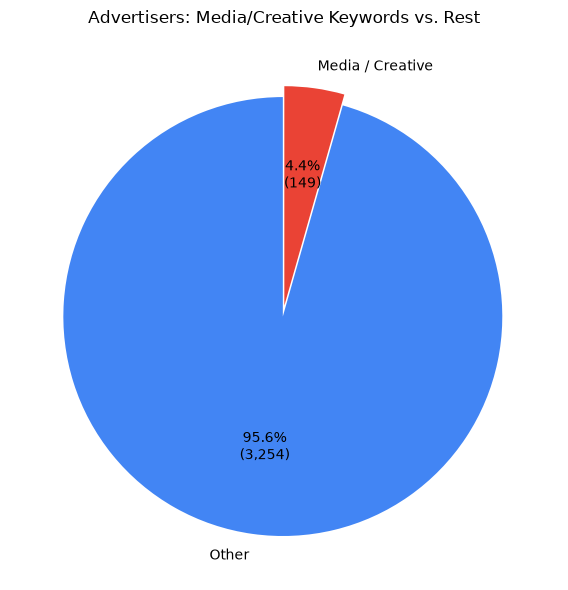

In [37]:
import matplotlib.pyplot as plt

keywords = "photo|video|films|creative|media"
is_media = df["Advertiser"].str.contains(keywords, case=False, na=False)


category_counts = (
    is_media.map({True: "Media / Creative", False: "Other"}).value_counts()
)


plt.figure(figsize=(6, 6))
plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct=lambda p: f"{p:.1f}%\n({int(p * sum(category_counts) / 100):,})",  
    startangle=90,
    colors=["#4285F4", "#EA4335"],
    explode=[0.05, 0],  
)

plt.title("Advertisers: Media/Creative Keywords vs. Rest")
plt.tight_layout()
plt.show()

The chart above was created with asistance from Google Gemini.

I can conclude from the pie chart above that very few of the adertisers were media and creative companies by name. While this count may not be 100% accurate it could be infered that it is close due to the large diference in count versus my expected number based on my liked posts. Since the majority of my liked posts were creative/media accounts, I had predicted the advertisers that targeted me to be the same. However, the data shown through the pie chart indicates this not to be true. I would now assume that factors such as age, gender, and location are more important in determining the advertisements that are displayed.